# ¿Cuándo despega un brote? El umbral R0 = 1

**Pregunta:** Aparece un primer caso en una población donde nadie es inmune. ¿Para qué tasas de contacto y de recuperación inicia un brote, y qué parte de la población debe ser inmune de antemano para que el brote fracase?

- **Nivel:** 1, Fundamentos
- **Requisitos:** tema 01-getting-started
- **Tiempo de lectura:** unos 25 minutos

## Objetivos

Al terminar este notebook puedes decir, solo a partir de $\beta$ y $\gamma$, si un brote despegará; ver el umbral en la salida del motor, tanto en qué tan rápido crecen los infectados la primera semana como en qué tan alto llega el pico; y calcular qué parte de la población debe ser inmune para detenerlo.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Este producto de ejemplo no publica ningún paquete propio: su método vive en `data-pipeline/pipeline/`, así que el notebook importa ese código por su ruta. Un producto importa su propio paquete de PyPI en su lugar (`pip install <paquete>==<versión>`).

La celda siguiente importa las herramientas y los módulos del pipeline, imprime las versiones y define el lector de los parámetros de los casos.

In [1]:
# las herramientas, sus versiones, los módulos del pipeline y el lector de los parámetros de los casos
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.baseline import peak_frac
from pipeline.model.sir import simulate

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los parámetros de los cinco casos del ejemplo.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce a partir de los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay un conjunto de datos de terceros, así que no aplica ninguna licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json` y `data/derived/manifests/<caso>.json`, solo por sus parámetros; cada curva que se muestra aquí la calcula el motor.

## Método

La razón de reproducción básica $R_0$ es el número de personas que infecta una persona infectada, en promedio, en una población donde todos son susceptibles (Diekmann, Heesterbeek y Metz, 1990). En el modelo SIR una persona infectada se encuentra con $\beta$ personas por día y sigue siendo infecciosa durante $1 / \gamma$ días, de modo que $R_0 = \beta / \gamma$. Al comienzo $S \approx N$, la ecuación de los infectados se vuelve $dI/dt \approx (\beta - \gamma) I$, e $I$ crece de forma exponencial a la tasa $\gamma (R_0 - 1)$ cuando $R_0 > 1$ y decae cuando $R_0 < 1$. Para los modelos compartimentales en general la condición $R_0 < 1$ es justamente la estabilidad del estado libre de enfermedad (van den Driessche y Watmough, 2002).

Si una parte $v$ de la población es inmune antes del brote, una persona infectada se encuentra con susceptibles solo durante una fracción $(1 - v)$ del tiempo y la razón efectiva es $R_0 (1 - v)$. Baja de 1 cuando $v > 1 - 1/R_0$, el umbral de rebaño. El motor no tiene un compartimento de inmunes, pero inmunizar una parte $v$ equivale a correrlo sobre una población de $(1 - v) N$ personas con la tasa de contacto $\beta (1 - v)$, porque la presión de infección $\beta / N$ queda entonces igual. El notebook usa esa equivalencia.

La primera celda imprime $R_0$ para los cinco casos archivados y, donde supera 1, el umbral de rebaño. No corre ninguna simulación; es la aritmética que el resto del notebook pondrá a prueba contra el motor.

In [2]:
# los cinco casos con R0 = beta / gamma y, donde R0 supera 1, el umbral de rebaño 1 - 1 / R0
for case_id in CASES:
    p = params_of(case_id)
    r0 = p.beta / p.gamma
    threshold = f"{1 - 1 / r0:.3f}" if r0 > 1 else "ninguno (R0 <= 1)"
    print(f"{case_id:18s} R0 = {r0:5.2f}   umbral de rebaño: {threshold}")

CTRL_degenerate    R0 =  2.00   umbral de rebaño: 0.500
EX01_subcritical   R0 =  0.72   umbral de rebaño: ninguno (R0 <= 1)
EX02_epidemic      R0 =  2.75   umbral de rebaño: 0.636
EX03_fast_burn     R0 =  6.00   umbral de rebaño: 0.833
EX04_slow_spread   R0 =  1.20   umbral de rebaño: 0.167


Solo el caso subcrítico, con 0,72, está bajo 1. El control tiene $R_0 = 2{,}00$ pero nadie infectado al principio, así que no hay nada que crezca, y los otros tres tienen $R_0$ de 1,20, 2,75 y 6,00. La celda siguiente corre el motor sobre cada caso con personas infectadas y divide el pico por el número de infectados del día 0. Si $R_0$ es el umbral, el caso subcrítico no debería crecer y los demás deberían crecer en un factor grande.

In [3]:
# corre los casos con infectados y compara cada pico con las personas infectadas al comienzo
for case_id in CASES:
    p = params_of(case_id)
    if p.I0 == 0:
        continue
    r = simulate(p)
    print(f"{case_id:18s} R0 = {p.beta / p.gamma:5.2f}  I0 = {p.I0:4.0f}", end="  ")
    print(f"pico {r.peak_I:7.0f} el día {r.t_peak:6.2f}  x{r.peak_I / p.I0:6.1f}")

EX01_subcritical   R0 =  0.72  I0 =   50  pico      50 el día   0.00  x   1.0
EX02_epidemic      R0 =  2.75  I0 =   50  pico   27345 el día  24.25  x 546.9
EX03_fast_burn     R0 =  6.00  I0 =  100  pico   55265 el día   9.25  x 552.7
EX04_slow_spread   R0 =  1.20  I0 =   50  pico    1521 el día  96.25  x  30.4


El caso subcrítico multiplica sus 50 infecciones iniciales por exactamente 1,0: su pico está en el día 0. La propagación lenta, con un $R_0$ solo 20 por ciento sobre 1, las multiplica por 30, y el caso epidémico y la combustión rápida por unas 550. El umbral se nota, pero tres casos son pocos para ver su forma. La celda siguiente recorre $R_0$ de 0,5 a 4 en pasos de 0,1, con la tasa de recuperación del caso epidémico fija y la tasa de contacto cambiando, y corre el motor en cada valor. Para cada corrida ajusta una recta al logaritmo de los infectados durante la primera semana, cuya pendiente es la tasa de crecimiento observada, y registra el pico como parte de la población. Imprime cuatro valores junto a la teoría: la tasa $\gamma (R_0 - 1)$ y el pico analítico de la línea base.

In [4]:
# recorre R0 de 0,5 a 4 con la tasa de recuperación del caso epidémico, y corre el motor en cada valor
base = params_of("EX02_epidemic")
r0_grid = np.linspace(0.5, 4.0, 36)
growth = []
peak_share = []
for r0 in r0_grid:
    r = simulate(replace(base, beta=r0 * base.gamma))
    growth.append(np.polyfit(r.t[:29], np.log(r.I[:29]), 1)[0])
    peak_share.append(r.peak_I / base.N)
baseline = [peak_frac(r0) for r0 in r0_grid]
for r0 in (0.5, 1.0, 2.0, 4.0):
    k = int(np.argmin(np.abs(r0_grid - r0)))
    print(f"R0 = {r0:3.1f}  crecimiento {growth[k]:+.3f}  gamma (R0 - 1) = {base.gamma * (r0 - 1):+.3f}", end="  ")
    print(f"parte en el pico {peak_share[k]:.4f}  analítico {baseline[k]:.4f}")

R0 = 0.5  crecimiento -0.101  gamma (R0 - 1) = -0.100  parte en el pico 0.0005  analítico 0.0000
R0 = 1.0  crecimiento -0.000  gamma (R0 - 1) = +0.000  parte en el pico 0.0005  analítico 0.0000
R0 = 2.0  crecimiento +0.195  gamma (R0 - 1) = +0.200  parte en el pico 0.1555  analítico 0.1534
R0 = 4.0  crecimiento +0.555  gamma (R0 - 1) = +0.600  parte en el pico 0.4137  analítico 0.4034


La celda siguiente dibuja la tasa de crecimiento y la parte en el pico contra $R_0$ en dos paneles, con el umbral $R_0 = 1$ marcado.

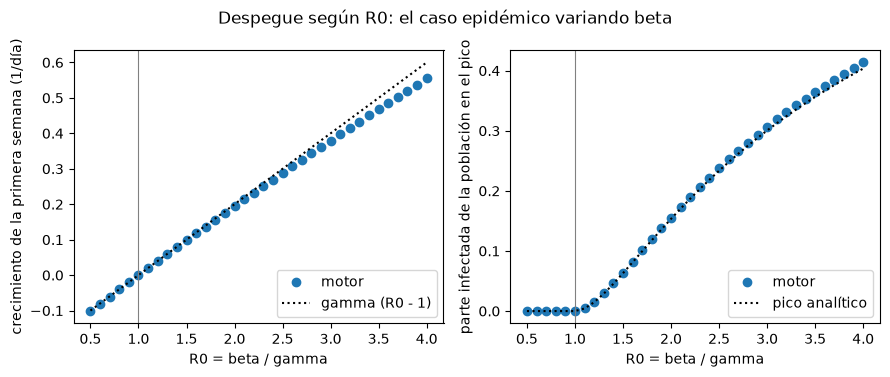

In [5]:
# dibuja el crecimiento de la primera semana y la parte en el pico contra R0, con el umbral R0 = 1
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.8))
left.plot(r0_grid, growth, "o", label="motor")
left.plot(r0_grid, base.gamma * (r0_grid - 1), "k:", label="gamma (R0 - 1)")
right.plot(r0_grid, peak_share, "o", label="motor")
right.plot(r0_grid, baseline, "k:", label="pico analítico")
ylabels = ("crecimiento de la primera semana (1/día)", "parte infectada de la población en el pico")
for ax, ylabel in zip((left, right), ylabels):
    ax.axvline(1.0, color="grey", linewidth=0.8)
    ax.set_xlabel("R0 = beta / gamma")
    ax.set_ylabel(ylabel)
    ax.legend()
fig.suptitle("Despegue según R0: el caso epidémico variando beta")
fig.tight_layout()
plt.show()

El panel izquierdo es el umbral mismo: la tasa de crecimiento de la primera semana cruza cero justo en $R_0 = 1$ y sigue la recta $\gamma (R_0 - 1)$, un poco por debajo con $R_0$ grande porque al terminar la semana los susceptibles ya han empezado a escasear. El panel derecho muestra qué poco importa una tasa alta justo sobre el umbral: el pico se queda en cerca de uno por ciento de la población o menos hasta $R_0 = 1{,}2$ y luego sube con fuerza, siguiendo el pico analítico de la línea base. La figura no muestra el tiempo. Un brote con $R_0$ apenas sobre 1 sí despega, pero qué tan tarde lo hace es lo que muestra la celda siguiente.

In [6]:
# mira de cerca el umbral: el motor con R0 = 0,9, 1,0, 1,1, 1,2 y 1,5
for r0 in (0.9, 1.0, 1.1, 1.2, 1.5):
    r = simulate(replace(base, beta=r0 * base.gamma))
    print(f"R0 = {r0:3.1f}  pico {r.peak_I:6.0f}  el día {r.t_peak:6.2f}  tasa de ataque {r.attack_rate:.4f}")

R0 = 0.9  pico     50  el día   0.00  tasa de ataque 0.0047
R0 = 1.0  pico     50  el día   0.00  tasa de ataque 0.0147
R0 = 1.1  pico    465  el día 160.00  tasa de ataque 0.0749
R0 = 1.2  pico   1520  el día 120.25  tasa de ataque 0.2542
R0 = 1.5  pico   6379  el día  64.50  tasa de ataque 0.5845


Con $R_0 = 0{,}9$ y con $R_0 = 1{,}0$ el pico son las 50 infecciones iniciales del día 0. Con $R_0 = 1{,}1$ los infectados todavía crecen cuando terminan los 160 días: el pico impreso, en el día 160,00, es el último día y no un pico verdadero. Con 1,2 el pico llega en el día 120,25 y con 1,5 en el día 64,50. Justo sobre el umbral el brote existe pero es lento, de modo que un horizonte demasiado corto lo confunde con la ausencia de brote. La última pregunta del notebook es el umbral de rebaño: la celda corre el caso epidémico con una parte $v$ de la población inmune, de 0 a 0,8 en pasos de 0,05, e imprime el umbral $1 - \gamma/\beta$ con la parte infectada para tres valores de $v$.

In [7]:
# inmuniza antes una parte v de la población: el mismo motor con contacto y población escalados por 1 - v
shares = np.linspace(0.0, 0.8, 17)
final_share = []
for v in shares:
    scaled = replace(base, beta=base.beta * (1 - v), N=base.N * (1 - v))
    final_share.append(simulate(scaled).R[-1] / base.N)
herd = 1 - base.gamma / base.beta
print(f"umbral de rebaño: {herd:.3f}")
for v in (0.3, 0.6, 0.7):
    k = int(np.argmin(np.abs(shares - v)))
    print(f"v = {v:.1f}  parte infectada {final_share[k]:.4f}")

umbral de rebaño: 0.636
v = 0.3  parte infectada 0.5446
v = 0.6  parte infectada 0.0496
v = 0.7  parte infectada 0.0028


La celda siguiente dibuja la parte infectada contra la parte inmune, con el umbral de rebaño marcado.

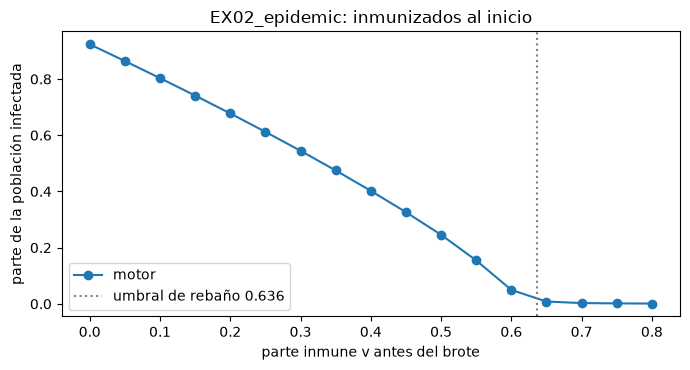

In [8]:
# dibuja la parte infectada de la población contra la parte inmune, con el umbral de rebaño
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(shares, final_share, "o-", label="motor")
ax.axvline(herd, color="grey", linestyle=":", label=f"umbral de rebaño {herd:.3f}")
ax.set_xlabel("parte inmune v antes del brote")
ax.set_ylabel("parte de la población infectada")
ax.set_title("EX02_epidemic: inmunizados al inicio")
ax.legend()
fig.tight_layout()
plt.show()

La curva cae con fuerza y llega al suelo en la línea punteada: con 30 por ciento de inmunes el brote todavía infecta 0,5446 de la población, con 60 por ciento solo 0,0496, y con 70 por ciento, pasado el umbral de rebaño de 0,636, 0,0028, que son las 50 infecciones iniciales y los pocos que ellas contagian. El umbral es el punto desde el cual el brote deja de poder alimentarse. La figura trata la inmunidad como perfecta y uniforme, y eso es un supuesto del modelo y no un hallazgo: una vacuna que protege solo a una parte de quienes la reciben, o inmunes que se agrupan, correrían la línea hacia la derecha.

## Resultados

**Respuesta:** Un brote despega exactamente cuando $R_0 = \beta / \gamma$ supera 1. En el motor la tasa de crecimiento de la primera semana es -0,101 por día con $R_0 = 0{,}5$, cerca de 0 con 1,0, 0,195 con 2,0 y 0,555 con 4,0, frente a los -0,100, 0,000, 0,200 y 0,600 teóricos de $\gamma (R_0 - 1)$. La propagación lenta, con $R_0 = 1{,}20$, multiplica sus 50 infecciones iniciales por 30,4 y alcanza su máximo el día 96,25, mientras que el caso subcrítico, con 0,72, nunca pasa de sus 50 iniciales. Para evitar un brote en el caso epidémico, con $R_0 = 2{,}75$, debe ser inmune de antemano una parte de 0,636 de la población: con 0,6 el brote todavía alcanza 0,0496 de la población y con 0,7 solo 0,0028.

El resultado vale para una población cerrada y bien mezclada con inmunidad perfecta y uniforme. Vale para el umbral; todavía no dice nada sobre qué tan grande se vuelve un brote sobre el umbral, que es la pregunta del notebook siguiente, y las corridas cerca del umbral mostraron que un horizonte corto esconde brotes lentos.

## Resumen

- Un brote despega cuando $R_0 = \beta / \gamma$ está sobre 1, y la tasa de crecimiento de la primera semana del motor sigue $\gamma (R_0 - 1)$ y cruza cero en 1.
- Justo sobre el umbral el brote es real pero lento: con $R_0 = 1{,}1$ no ha alcanzado su máximo a los 160 días.
- La parte que debe ser inmune para detener el caso epidémico es $1 - 1/R_0 = 0{,}636$.
- Siguiente: qué tan grande se vuelve el brote una vez que despega, en el notebook 02 de este tema.

## Referencias

- Diekmann, O., Heesterbeek, J. A. P. y Metz, J. A. J. (1990). On the definition and the computation of the basic reproduction ratio R0 in models for infectious diseases in heterogeneous populations. Journal of Mathematical Biology. https://doi.org/10.1007/BF00178324
- van den Driessche, P. y Watmough, J. (2002). Reproduction numbers and sub-threshold endemic equilibria for compartmental models of disease transmission. Mathematical Biosciences. https://doi.org/10.1016/S0025-5564(02)00108-6
- Kermack, W. O. y McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- NumPy, https://pypi.org/project/numpy/ (fijado en `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (fijado en `notebooks/requirements.txt`).
- El motor y la línea base de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`, `pipeline/model/baseline.py`).